# Trabajo Final ML1 - Impacto de Anomalías Climáticas en el Rendimiento Agrícola
### Predicción contrafactual de estrés hídrico: ¿Cómo afecta un aumento del 20% en días secos durante la fase vegetativa?

**Objetivo:** Desarrollar modelos de Machine Learning supervisados para predecir el rendimiento (`Yield (kg/ha)`) y evaluar mediante **Inferencia Contrafactual (What-If Stress Testing)** el impacto agronómico de un incremento del 20% en la variable `Total_Dry_Days_Vegetative (days)`.

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Carga y Exploración del Dataset (`df_procesado.xlsx`)

In [11]:
df = pd.read_excel('df_procesado.xlsx')
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head(3)

Dimensiones: 765 filas x 43 columnas


,Location_Harvest,Municipality,State,Harvest,Year,Precipitation (mm),Atmospheric_Pressure (kPa),Solar_Radiation (KJ/mÂ²),Air_Temperature (Â°C),Max_Temperature (Â°C),...,Sand_30-60cm (g/kg),Silt_0-5cm (g/kg),Silt_5-15cm (g/kg),Silt_15-30cm (g/kg),Silt_30-60cm (g/kg),Bulk_Density_0-5cm (cg/cmÂ³),Bulk_Density_5-15cm (cg/cmÂ³),Bulk_Density_15-30cm (cg/cmÂ³),Bulk_Density_30-60cm (cg/cmÂ³),Yield (kg/ha)
0,AGUA BOA_Harvest_2008,AGUA BOA,MT,2007/2008,2008,3150205761316872,9597380658436214,8404249484536082,25926594650205764,26581430041152268,...,5716,1332,1274,1200,1206,1260,1288,1308,1322,31200
1,ALTO PARAISO DE GOIAS_Harvest_2008,ALTO PARAISO DE GOIAS,GO,2007/2008,2008,25758547008547008,8746601495726497,7640081095596133,21645352564102564,22425961538461536,...,2914,2908,2916,2752,2430,1270,1294,1308,1288,30000
2,BRASILIA_Harvest_2008,BRASILIA,DF,2007/2008,2008,26980224478888292,8849439337252807,805257962466488,2237161945483699,23034206306787816,...,2196,2796,2674,2630,2340,1202,1210,1234,1210,31500


## 2. Preparación de Variables Predictoras (X) y Variable Objetivo (y)

In [12]:
target_col = 'Yield (kg/ha)'
cols_descartar = [target_col, 'Location_Harvest', 'Harvest']
X = df.drop(columns=[c for c in cols_descartar if c in df.columns])
y = df[target_col]

cat_cols = ['State', 'Municipality']
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"Target: {target_col} | Features numéricas: {len(num_cols)} | Features categóricas: {cat_cols}")

Target: Yield (kg/ha) | Features numéricas: 38 | Features categóricas: ['State', 'Municipality']


## 3. Entrenamiento y Validación Cruzada de Modelos (5-Fold CV)

In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

modelos = {
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('reg', RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1))
    ]),
    'XGBoost': Pipeline([
        ('prep', preprocessor),
        ('reg', XGBRegressor(n_estimators=120, learning_rate=0.05, max_depth=4, subsample=0.85, random_state=42, n_jobs=-1))
    ])
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
for name, pipe in modelos.items():
    cv_res = cross_validate(pipe, X, y, cv=cv, scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error'])
    r2 = cv_res['test_r2'].mean()
    mae = -cv_res['test_neg_mean_absolute_error'].mean()
    rmse = -cv_res['test_neg_root_mean_squared_error'].mean()
    print(f"{name:15s} -> R2: {r2:.4f} | MAE: {mae:.2f} kg/ha | RMSE: {rmse:.2f} kg/ha")

Random Forest   -> R2: 0.3832 | MAE: 2686.06 kg/ha | RMSE: 3782.69 kg/ha
XGBoost         -> R2: 0.4046 | MAE: 2622.38 kg/ha | RMSE: 3718.75 kg/ha


## 4. Simulación de Anomalía Climática: +20% en Días Secos Vegetativos
> **Consistencia física de las variables:** La variable de interacción `Dry_Stress_Vegetative (days²)` corresponde exactamente al producto `Max_Dry_Days_Vegetative * Total_Dry_Days_Vegetative`. Por lo tanto, al incrementar los días secos, actualizamos también la variable derivada para reflejar el efecto acumulado real.

In [8]:
# Entrenamos el modelo final con todo el dataset
modelo_final = modelos['XGBoost']
modelo_final.fit(X, y)

# 1. Predicción base
pred_base = modelo_final.predict(X)

# 2. Simulación de anomalía (+20% de sequía en fase vegetativa)
X_shock = X.copy()
col_dias_secos = 'Total_Dry_Days_Vegetative (days)'
X_shock[col_dias_secos] = X_shock[col_dias_secos] * 1.20

# Propagación consistente de la variable compuesta
col_stress = [c for c in X.columns if 'Dry_Stress_Vegetative' in c][0]
X_shock[col_stress] = X_shock['Max_Dry_Days_Vegetative (days)'] * X_shock[col_dias_secos]

# 3. Predicción bajo escenario de estrés
pred_shock = modelo_final.predict(X_shock)
delta_rendimiento = pred_shock - pred_base
pct_variacion = (delta_rendimiento / pred_base) * 100

print(f"Rendimiento Promedio Base:      {pred_base.mean():,.2f} kg/ha")
print(f"Rendimiento Promedio Simulado:  {pred_shock.mean():,.2f} kg/ha")
print(f"Impacto Promedio (Delta):       {delta_rendimiento.mean():,.2f} kg/ha ({pct_variacion.mean():.2f}%)")
print(f"Caída Máxima Local Registrada:  {delta_rendimiento.min():,.2f} kg/ha ({pct_variacion.min():.2f}%)")

Rendimiento Promedio Base:      31,420.17 kg/ha
Rendimiento Promedio Simulado:  31,106.36 kg/ha
Impacto Promedio (Delta):       -313.80 kg/ha (-1.05%)
Caída Máxima Local Registrada:  -3,815.00 kg/ha (-14.38%)


## 5. Visualización y Análisis Geográfico del Impacto por Estado

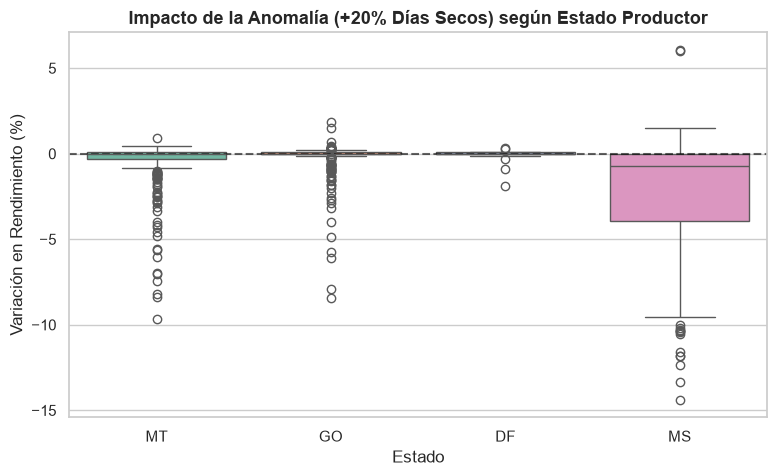

,Casos,Rendimiento_Base_Medio,Delta_Medio_kg_ha,Variacion_Media_Porc,Caida_Maxima_Porc
State,,,,,
DF,17,33047.476562,-42.203354,-0.120738,-1.876571
GO,238,32431.654297,-94.872566,-0.290235,-8.435435
MS,241,29859.646484,-708.138855,-2.422911,-14.382092
MT,269,31820.490234,-171.380524,-0.542651,-9.676234


In [9]:
df_analisis = pd.DataFrame({
    'State': df['State'],
    'Municipality': df['Municipality'],
    'Rendimiento_Base': pred_base,
    'Delta_kg_ha': delta_rendimiento,
    'Variacion_%': pct_variacion
})

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_analisis, x='State', y='Variacion_%', hue='State', palette='Set2', legend=False)
plt.axhline(0, color='black', linestyle='--', alpha=0.6)
plt.title('Impacto de la Anomalía (+20% Días Secos) según Estado Productor', fontsize=13, fontweight='bold')
plt.xlabel('Estado')
plt.ylabel('Variación en Rendimiento (%)')
plt.show()

resumen_estado = df_analisis.groupby('State').agg(
    Casos=('Delta_kg_ha', 'count'),
    Rendimiento_Base_Medio=('Rendimiento_Base', 'mean'),
    Delta_Medio_kg_ha=('Delta_kg_ha', 'mean'),
    Variacion_Media_Porc=('Variacion_%', 'mean'),
    Caida_Maxima_Porc=('Variacion_%', 'min')
)
resumen_estado